# RetailRocket
Проверяем, дают ли совпадающие интервалы активности товаров информацию сверх популярности. 

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd

SEED = 42
MAX_USERS = 1000
DAY = 86_400_000
RANK = 16
HISTORY = 20

path = Path("../data/events.csv")
raw = pd.read_csv(path, usecols=["timestamp", "visitorid", "event", "itemid"])
print(raw.event.value_counts())

views = raw.loc[raw.event == "view", ["timestamp", "visitorid", "itemid"]]
views = views.sort_values("timestamp", kind="stable")
times, users, items = (views[c].to_numpy() for c in views)

start, end = times[0], times[-1] + 1
bounds = start + (end - start) * np.array([0, 40, 80, 90, 100]) // 100
cuts = times.searchsorted(bounds)
prefix = cuts[1]
catalog = np.unique(items[:prefix])
ids = pd.Index(catalog).get_indexer(items)
print("Границы UTC:", pd.to_datetime(bounds, unit="ms", utc=True).tolist())

event
view           2664312
addtocart        69332
transaction      22457
Name: count, dtype: int64


Границы UTC: [Timestamp('2015-05-03 03:00:11.289000+0000', tz='UTC'), Timestamp('2015-06-27 07:48:01.889000+0000', tz='UTC'), Timestamp('2015-08-21 12:35:52.489000+0000', tz='UTC'), Timestamp('2015-09-04 07:47:50.139000+0000', tz='UTC'), Timestamp('2015-09-18 02:59:47.789000+0000', tz='UTC')]


## Разбиение и каталог

Берём в каталог товары из первых 40% периода. Смотрим, сколько просмотров следующих периодов он покрывает.

In [2]:
for period, lo, hi in zip(["prefix", "train", "validation", "test"], cuts[:-1], cuts[1:]):
    lengths = pd.Series(users[lo:hi]).value_counts()
    outside = ids[lo:hi] < 0
    print(period, dict(views=hi-lo, users=len(lengths), items=len(np.unique(items[lo:hi])),
                       outside_events=round(outside.mean(), 4),
                       outside_unique=round(len(np.unique(items[lo:hi][outside])) / len(np.unique(items[lo:hi])), 4),
                       user_length_p50_p90=lengths.quantile([.5, .9]).tolist()))

prefix {'views': np.int64(1092810), 'users': 570420, 'items': 158025, 'outside_events': np.float64(0.0), 'outside_unique': 0.0, 'user_length_p50_p90': [1.0, 3.0]}
train {'views': np.int64(1098497), 'users': 609225, 'items': 160619, 'outside_events': np.float64(0.121), 'outside_unique': 0.3578, 'user_length_p50_p90': [1.0, 3.0]}
validation {'views': np.int64(237412), 'users': 140969, 'items': 72585, 'outside_events': np.float64(0.1551), 'outside_unique': 0.2639, 'user_length_p50_p90': [1.0, 3.0]}


test {'views': np.int64(235593), 'users': 139694, 'items': 71622, 'outside_events': np.float64(0.1862), 'outside_unique': 0.2822, 'user_length_p50_p90': [1.0, 3.0]}


In [3]:
def activity(hours):
    width = hours * DAY // 24
    bins = (times[:prefix] - start) // width
    count = int((bounds[1] - start + width - 1) // width)
    matrix = np.zeros((len(catalog), count), dtype=np.uint8)
    matrix[ids[:prefix], bins] = 1
    return matrix

for hours in [6, 24]:
    X = activity(hours)
    active = X.sum(axis=1)
    print(hours, "ч", X.shape, "плотность", round(X.mean(), 4),
          "доля с одним интервалом", round((active == 1).mean(), 4),
          "доля активных в ≥90% интервалов", round((active >= .9 * X.shape[1]).mean(), 4))

6 ч (158025, 221) плотность 0.0231 доля с одним интервалом 0.423 доля активных в ≥90% интервалов 0.0
24 ч (158025, 56) плотность 0.0764 доля с одним интервалом 0.4297 доля активных в ≥90% интервалов 0.0011


### Активность товаров

Разобьём товары на три группы по числу просмотров и сравним, сколько дней они были активны.

Верхний 1% · медиана активных суток: 40.0 · заполненность: 71.3% · повторные просмотры в ячейках: 71.9%


Следующие 9% · медиана активных суток: 16.0 · заполненность: 31.1% · повторные просмотры в ячейках: 42.1%
Остальные 90% · медиана активных суток: 2.0 · заполненность: 4.6% · повторные просмотры в ячейках: 17.0%


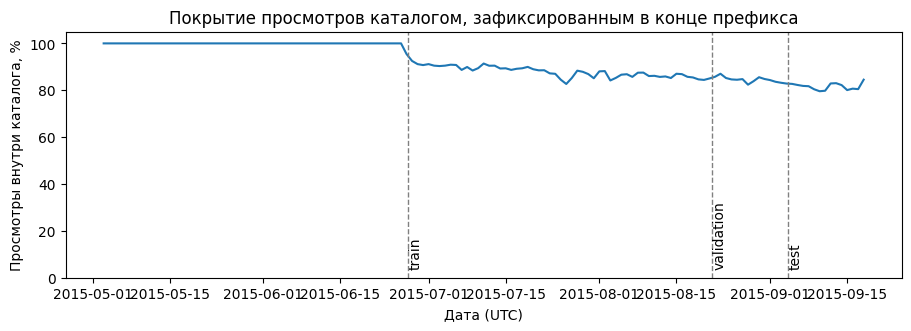

In [4]:
import matplotlib.pyplot as plt

counts_prefix = np.bincount(ids[:prefix], minlength=len(catalog))
pop_order = np.argsort(-counts_prefix, kind="stable")
active_days = X.sum(axis=1)
groups = np.split(pop_order, [len(catalog) // 100, len(catalog) // 10])
for name, group in zip(["Верхний 1%", "Следующие 9%", "Остальные 90%"], groups):
    occupied = active_days[group].sum()
    print(name, "· медиана активных суток:", np.median(active_days[group]),
          "· заполненность:", f"{occupied / (len(group) * X.shape[1]):.1%}",
          "· повторные просмотры в ячейках:", f"{1 - occupied / counts_prefix[group].sum():.1%}")

daily = pd.DataFrame({"day": pd.to_datetime(times, unit="ms", utc=True).floor("D"), "known": ids >= 0})
coverage = daily.groupby("day").known.mean()
fig, ax = plt.subplots(figsize=(9, 3.2), layout="constrained")
ax.plot(coverage.index, 100 * coverage)
for boundary, label in zip(bounds[1:-1], ["train", "validation", "test"]):
    date = pd.to_datetime(boundary, unit="ms", utc=True)
    ax.axvline(date, color="grey", ls="--", lw=1)
    ax.text(date, 5, label, rotation=90)
ax.set(ylim=(0, 105), ylabel="Просмотры внутри каталога, %", xlabel="Дата (UTC)",
       title="Покрытие просмотров каталогом, зафиксированным в конце префикса")
plt.show()

У верхнего 1% товаров медиана — 40 активных дней, у нижних 90% — всего 2. При этом 71,9% просмотров самых популярных товаров попадают в уже занятую ячейку. В следующем эксперименте стоит попробовать `log1p(count)`, чтобы учитывать число просмотров за день.

## Векторы товаров

Берём 16 компонент SVD дневной матрицы и нормируем векторы. Для Shuffle перемешиваем дни отдельно у каждого товара. Так число активных дней сохраняется. Для Random берём случайные векторы той же размерности и нормы.

In [5]:
def normalize(rows):
    return rows / np.maximum(np.linalg.norm(rows, axis=1, keepdims=True), 1e-12)

def embed(matrix):
    matrix = matrix.astype(np.float32)
    _, vectors = np.linalg.eigh(matrix.T @ matrix)
    return np.ascontiguousarray(normalize(matrix @ vectors[:, -RANK:]))

rng = np.random.default_rng(SEED)
z = embed(X)
shuffled = rng.permuted(X, axis=1)
assert np.array_equal(X.sum(axis=1), shuffled.sum(axis=1))
random_vectors = rng.standard_normal(z.shape, dtype=np.float32)
embeddings = {
    "SVD": z,
    "Shuffle": embed(shuffled),
    "Random": normalize(random_vectors) * np.linalg.norm(z, axis=1, keepdims=True),
}

## Следующий просмотр

Берём до 1000 пользователей на период и ранжируем весь каталог. К популярности добавляем косинус с усреднённым вектором последних 20 просмотров. Веса фиксированы, проекция единичная.

Если история пуста, используем RecentPopular. У PopMatched то же правило: сравнение с ним показывает, что даёт добавление сходства.

In [6]:
def target_rank(scores, target):
    value = scores[target]
    ahead = np.count_nonzero(scores > value)
    tied_before = np.count_nonzero(scores[:target] == value)  # при равенстве первым идёт меньший itemid
    return 1 + ahead + tied_before

def evaluate(lo, hi, seed):
    visitors = np.unique(users[lo:hi])
    rng = np.random.default_rng(seed)
    selected = visitors
    if MAX_USERS is not None:
        size = min(MAX_USERS, len(visitors))
        selected = rng.choice(visitors, size, replace=False)
    selected_rows = np.flatnonzero(np.isin(users[:hi], selected) & (ids[:hi] >= 0))
    histories = {}
    counts = np.zeros(len(catalog), dtype=np.int64)
    recent = counts.copy()
    last = left = 0
    rows = []
    cold = targets = 0
    for time, group in pd.Series(selected_rows, index=times[selected_rows]).groupby(level=0, sort=False):
        positions = group.to_numpy()
        if positions[0] >= lo:
            stop = times.searchsorted(time)
            window = times.searchsorted(time - 7 * DAY)
            added = ids[last:stop]
            expired = ids[left:window]
            np.add.at(counts, added[added >= 0], 1)
            np.add.at(recent, added[added >= 0], 1)
            np.subtract.at(recent, expired[expired >= 0], 1)
            last, left = stop, window
            pop = np.log1p(counts) + np.log1p(recent)
            for pos in positions:
                user, target = users[pos], ids[pos]
                history = histories.get(user, [])
                targets += 1
                cold += int(len(history) == 0)
                scores = {"MostPopular": counts, "RecentPopular": recent, "Pop": pop}
                scores["PopMatched"] = pop if history else recent
                for name, vectors in embeddings.items():
                    if history:
                        profile = vectors[history].mean(axis=0)
                        similarity = vectors @ (profile / max(np.linalg.norm(profile), 1e-12))
                        scores[name] = pop + similarity
                    else:
                        scores[name] = recent
                for name, values in scores.items():
                    rows.append((pos, user, bool(history), name, target_rank(values, target)))
        # События с одинаковым временем добавляем после всех прогнозов группы.
        for pos in positions:
            history = histories.setdefault(users[pos], [])
            history.append(ids[pos])
            del history[:-HISTORY]
    frame = pd.DataFrame(rows, columns=["event", "user", "warm", "model", "rank"])
    frame["Recall@10"] = frame["rank"] <= 10
    frame["NDCG@10"] = np.where(frame["Recall@10"], 1 / np.log2(frame["rank"] + 1), 0.)
    per_user = frame.groupby(["user", "model"])[["Recall@10", "NDCG@10"]].mean()
    print("Выбрано пользователей:", len(selected), "с доступной целью:", frame.user.nunique(),
          "целей:", targets, "без истории:", cold)
    return per_user.groupby("model").mean(), frame

results, events = {}, {}
for label, lo, hi, seed in [("validation", cuts[2], cuts[3], SEED), ("test", cuts[3], cuts[4], SEED+1)]:
    print(label)
    results[label], events[label] = evaluate(lo, hi, seed)
    print(results[label].round(6))

validation


Выбрано пользователей: 1000 с доступной целью: 850 целей: 1400 без истории: 767
               Recall@10   NDCG@10
model                             
MostPopular     0.012235  0.008663
Pop             0.016353  0.010945
PopMatched      0.017529  0.011461
Random          0.018902  0.012069
RecentPopular   0.014882  0.010527
SVD             0.017529  0.011474
Shuffle         0.017529  0.011474
test


Выбрано пользователей: 1000 с доступной целью: 846 целей: 1370 без истории: 767
               Recall@10   NDCG@10
model                             
MostPopular     0.010807  0.006897
Pop             0.015929  0.008792
PopMatched      0.014156  0.008812
Random          0.015929  0.009629
RecentPopular   0.013987  0.008707
SVD             0.014156  0.008812
Shuffle         0.014156  0.008812


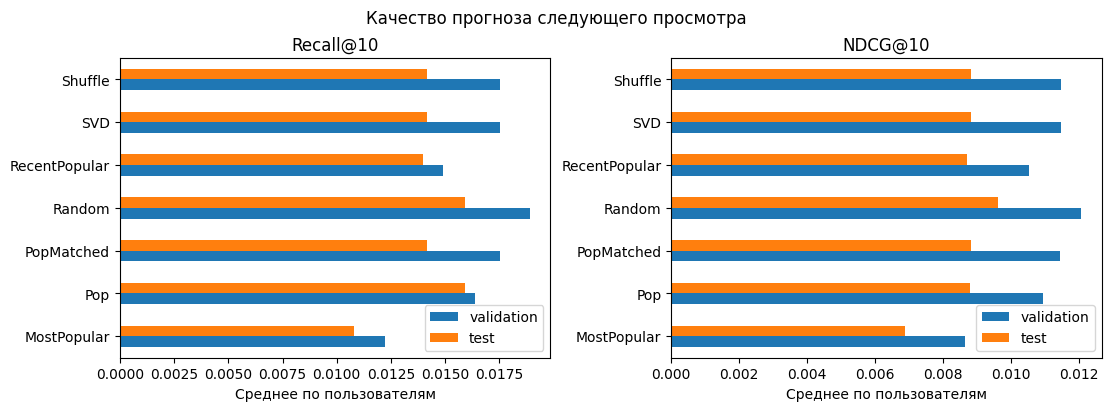

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for ax, metric in zip(axes, ["Recall@10", "NDCG@10"]):
    pd.DataFrame({split: table[metric] for split, table in results.items()}).plot.barh(ax=ax)
    ax.set(title=metric, ylabel="", xlabel="Среднее по пользователям")
fig.suptitle("Качество прогноза следующего просмотра")
plt.show()

validation с историей: 633 ранг различается: 618 различается вклад в NDCG@10: 0 попаданий SVD / Shuffle: 6 6
test с историей: 603 ранг различается: 586 различается вклад в NDCG@10: 0 попаданий SVD / Shuffle: 3 3


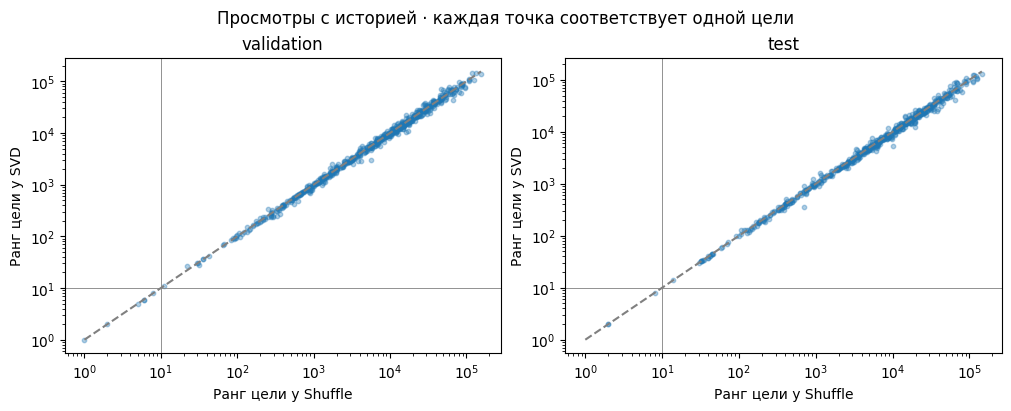

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
for ax, (split, frame) in zip(axes, events.items()):
    ranks = frame.loc[frame.warm].pivot(index="event", columns="model", values="rank")
    svd, shuffle = ranks["SVD"], ranks["Shuffle"]
    changed = svd != shuffle
    visible = changed & ((svd <= 10) | (shuffle <= 10))
    print(split, "с историей:", len(ranks), "ранг различается:", changed.sum(),
          "различается вклад в NDCG@10:", visible.sum(),
          "попаданий SVD / Shuffle:", (svd <= 10).sum(), (shuffle <= 10).sum())
    ax.scatter(shuffle, svd, s=10, alpha=.35)
    limit = max(shuffle.max(), svd.max())
    ax.plot([1, limit], [1, limit], color="gray", linestyle="--")
    ax.axhline(10, color="gray", linewidth=.6)
    ax.axvline(10, color="gray", linewidth=.6)
    ax.set(xscale="log", yscale="log", title=split, xlabel="Ранг цели у Shuffle", ylabel="Ранг цели у SVD")
fig.suptitle("Просмотры с историей · каждая точка соответствует одной цели")
plt.show()

## Что получилось

На тесте у SVD и PopMatched совпали обе метрики до шестого знака. На валидации разница в NDCG@10 тоже мала: 0,011474 против 0,011461.

SVD и Shuffle дали разные места товару в 586 из 603 тестовых просмотров с историей. В десятку попали всего три раза, каждый раз на одинаковое место. Поэтому разницы в топ-10 на этой выборке мы не увидели.